# **LinkedList**

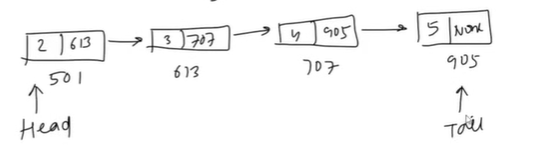

To Do list
---

What is LinkedList?

Node

Create a LinkedList

len

insert from head

traverse/print

insert from tail(append)

insert in middle(after)

clear

delete from head

delete from tail(pop)

delete by value(remove)


search by value(find)

delete by index -> del l[0]

search by index(indexing)

<!-- @format -->
What is LinkedList?

Linear Data structure, and store data in non-continuous memory location

It is a collection of Nodes.

Node is a object , have two parts (data and address)

How does it work?
Collection of nodes: (data|address) -> object
data can be any value.
address holds address of next node.
LinkedList nodes are not store in continuous memory

1st node is known as **head** and last is known as **tail**

Why should we use LinkedList?
When should we not use Array?
Insertion , Deletion requires shifts for all items after the position of new item.

When we perform **write** operation in array, it is always **O(n)**.
example : ToDo list (LinkedList is good as compare with Array).

LinkedList **write** order is always **O(1)** -> constant.

In case of dynamic Array more wastage of memory can be seen.

Using LinkedList can create Stack, Queue, Doubly LinkedList, Circular LinkedList.

Array is good in case of read data structure.

LinkedList drawback:
Read operations - O(n) as all node address store in anoter previous node and it means i always need to start from the begeining.

Array is good for read or seach then it is O(1)

When I create write operation we can think of LinkedList.

**4 main operation in LinkedList**

Insert -> head ,tail(append), middle (insert)

Traverse -> print

Delete -> head, tail(pop), value(remove), index

Search -> value, index

Other operations

max, reverse...

LinkedList is good for insert and update O(1) , read is slow O(n)
Array is good for read is good , insert and update is slow.



### **Node**

How to create individual nodes and how to connect them to form a linkedlist.

In [4]:
class Node:
    def __init__(self, value):
        self.data = value
        self.next = None

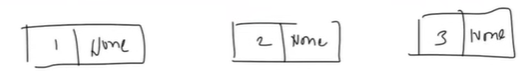

In [5]:
a = Node(1)
b = Node(2)
c = Node(3)

In [6]:
print(a.next)
id(b)

None


2041711392912

In [7]:
# Create a linkedlist
a.next = b
b.next = c

In [8]:
print(a.next)

In [9]:
int(0x0000025255FE6AD0) # address of b

2552653310672

---

In [10]:
class Node:
    def __init__(self, value):
        self.data = value
        self.next = None

In [118]:
class LinkedList:
    def __init__(self):

        # create a empty linkedlist (there are 0 nodes)
        # how to find if linkedlist is empty -> using head means it is going to be none.

        self.head = None
        self.n = 0  # how many nodes in linkedlist

    # length of the linkedlist is number of nodes in linkedlist
    def __len__(self):
        return self.n

    # Insertion from head
    def insert_head(self, value):
        # create a new node
        new_node = Node(value)

        # create connection
        new_node.next = self.head

        # reassign head
        self.head = new_node

        # increment n
        self.n = self.n + 1

    # insert from tail , start from head and traverse till taill and add address of new node
    def append(self, value):

        # empty linkedlist
        if self.head == None:
            self.insert_head(value)
            return

        new_node = Node(value)
        current = self.head
        # move untill current is last node
        while current.next is not None:
            current = current.next

        # current is now the last node
        current.next = new_node
        self.n += 1

    # insert value somewhere in given linkedlist and not beginning or end after matched value
    def insert_after(self, after, value):
        new_node = Node(value)
        curr = self.head

        while curr != None:
            if curr.data == after:
                break
            curr = curr.next

        # Case 1 item found
        if curr != None:
            new_node.next = curr.next
            curr.next = new_node
            self.n += 1
        else:
            return "item not found"
        # loop goes till end -> curr -> None

    # empty a given linked list
    def clear(self):
        self.head = None
        self.n = 0

    # delete from end
    def pop(self):

        # empty linked list
        if self.head == None:
            return "Empty LinkedList"
        curr = self.head

        # check if linkedlist has one item
        if curr.next == None:
            return self.delete_head()

        while curr.next.next != None:
            curr = curr.next

        # curr 2nd last node
        curr.next = None
        self.n -= 1

    # delete head node
    def delete_head(self):
        # empty list
        if self.head == None:
            return "Empty LinkedList."

        self.head = self.head.next
        self.n -= 1

    # delete item based on passed value
    def delete_val(self, val):
        # empty list
        if self.head == None:
            return "Empty LinkedList"

        # value has been found in first node.
        if self.head.data == val:
            return self.delete_head()

        curr = self.head

        while curr.next != None:
            if curr.next.data == val:
                break

            curr = curr.next

        if curr.next == None:
            return f"{val} is not present in LinkedList."

        curr.next = curr.next.next
        self.n -= 1

    # search a value
    def search_val(self, val):
        if self.head == None:
            return "Empty LinkedList"
        curr = self.head
        i = 0
        while curr != None:
            if curr.data == val:

                return f"{val} value has been found in index position {i}"

            curr = curr.next
            i += 1

        if curr == None:
            return f"{val} is not in LinkedList"

    """
    Write a python program to find the maximum value in a linked list and replace it with a given value.
    - Assume that the linkedlist is populated with whole numbers and there is only one maximum value in the Linked List.
    """

    def search_replace(self, val):
        if self.head == None:
            return "Empty LinkedList"

        curr = self.head

        max_val = self.head.data
        max_node_addr = curr

        while curr.next != None:
            if curr.data > max_val:
                max_val = curr.data
                max_node_addr = curr
            curr = curr.next

        max_node_addr.data = val

        return

    """ 
    Given a linked list of characters. Write a function to return a new string that is created by appending all the characters given in the linked list as per the runs given below.
    
    # Rules
    * Replace '*' or '/' by single space
    * In case of two consecutive occurances of '*' or '/', replace those two occurrences by a single space 
    * convert the next character to upper case.
    
    # Assume that ->
    * There will not be more than two consecutive occurences of '*' or '/' 
    * he linked list will always end with an alphabet
    
    # Sample Input
    A,n,*,/,a,p,p,l,e,*,a,/,day,*,*,k,e,e,p,s,/,*,a,/,/,d,o,c,t,o,r,*,A,w,a,y
    
    # Expected Output
    An Apple a day Keeps A Doctor Away    
    
    """

    def change_sent(self):
        temp = self.head

        while temp != None:

            if temp.data == "*" or temp.data == "/":
                temp.data = " "

                if temp.next.data == "*" or temp.next.data == "/":
                    temp.next.next.data = temp.next.next.data.upper()
                    temp.next = temp.next.next
            temp = temp.next

    """ 
    reverse a linked list containing integer data (in place reversal)
    """

    def reverse(self):
        prev_node = None
        curr_node = self.head

        while curr_node != None:
            next_node = curr_node.next
            curr_node.next = prev_node
            prev_node = curr_node
            curr_node = next_node

        # update head
        self.head = prev_node

    """ 
    Given a linked list containing whole numbers, write a python function which finds and return the sum of all the elements at the odd position in the given linked list
    """

    def sum_odd_nodes_val(self):
        if self.head == None:
            return "Empty Linked List"

        i = 0
        sum_odd_index = 0

        curr = self.head

        while curr != None:
            if i % 2 != 0:
                sum_odd_index += curr.data
            i += 1
            curr = curr.next
        return sum_odd_index

    """ 
    check the output of following function when head node of function when head node of following linked list is passed as input?
    1->2->3->4->5
    def fun(head):
        if head == None:
            return
        if head.next.next != None:
            print(head.data, " " , end= "")
            fun(head.next)
        print(head.data, " ", end= "")
        
    explanation:
    call 1:
        head = 1
        head.next.next = 3  
        print(1)
        fun(2)
        
    call 2:
        head = 2
        head.next.next = 4  
        print(2)
        fun(3)
        
    call 3:
        head = 3
        head.next.next = 5 
        print(3)
        fun(4)
        
    call 4:
        head = 4
        head.next.next = X (this will fail and next line of code won't execute)
        but this function call will complete its execution and execute the last print
        
                
    print (NOTE: output will be in one line and it will show a final output ):
    after first loop : 1  
    after second loop : 1 2
    after third loop : 1 2 3
    after fourth loop : 1 2 3 4 --> so after fun(4) execution it will print 4 and return None
    execute fun(3) : 1 2 3 4 3 --> so after fun(3) execution it will print 3 and return None
    execute fun(2) : 1 2 3 4 3 2 --> so after fun(2) execution it will print 2 and return None
    execute fun(1) : 1 2 3 4 3 2 1--> so after fun(1) execution it will print 1 and return None
    
    Final output: 1 2 3 4 3 2 1
    """

    # search using index
    def __getitem__(self, index):

        curr = self.head
        pos = 0

        while curr != None:
            if pos == index:
                return curr.data
            curr = curr.next
            pos = pos + 1
        return "Index Error"

    # def insert(self, pos, value):
    #     # invalid position
    #     if pos < 0 or pos > self.n:
    #         raise IndexError("Invalid Position")
    #     # empty list
    #     if self.head == None:
    #         self.insert_head(value)
    #         return
    #     # add at the beginning
    #     if pos == 0:
    #         self.insert_head(value)
    #         return
    #     # insert at the end
    #     if pos == self.n:
    #         self.append(value)
    #         return
    #     # insert to a valid position
    #     new_node = Node(value)
    #     curr = self.head
    #     i = 1
    #     while i != pos:
    #         curr = curr.next
    #         i += 1
    #     new_node.next = curr.next
    #     curr.next = new_node
    #     self.n += 1

    # traverse
    def __str__(self):
        current = self.head
        result = ""
        while current != None:
            result = result + str(current.data) + "->"
            current = current.next
        return result[:-2]

In [121]:
L = LinkedList()

In [112]:
L.insert_head(5)
L.insert_head(4)
L.insert_head(3)
L.insert_head(2)
L.insert_head(1)

In [122]:
# A,n,*,/,a,p,p,l,e,*,a,/,day,*,*,k,e,e,p,s,/,*,a,/,/,d,o,c,t,o,r,*,A,w,a,y
L.append('A')
L.append('n')
L.append('*')
L.append('/')
L.append('a')
L.append('p')
L.append('p')
L.append('l')
L.append('e')
L.append('*')
L.append('a')
L.append('/')
L.append('day')
L.append('*')
L.append('*')
L.append('k')
L.append('e')
L.append('e')
L.append('p')
L.append('s')
L.append('/')
L.append('*')
L.append('a')
L.append('/')
L.append('/')
L.append('d')
L.append('o')
L.append('c')
L.append('t')
L.append('o')
L.append('r')
L.append('*')
L.append('A')
L.append('w')
L.append('a')
L.append('y')


In [125]:
print(L)

A->n-> ->A->p->p->l->e-> ->a-> ->day-> ->K->e->e->p->s-> ->A-> ->D->o->c->t->o->r-> ->A->w->a->y


In [124]:
L.change_sent()

In [116]:
L.reverse()

In [93]:
L.sum_odd_nodes_val()

4

In [73]:
L.search_replace(10)

In [52]:
L[1]

3

In [40]:
L.search_val(11)


'Empty LinkedList'

In [175]:
len(L)

4

In [210]:
L.delete_val(4)

In [128]:
L.insert_after(6,100)

'item not found'

In [184]:
L.pop()

'Empty LinkedList'

In [133]:
L.clear()

In [120]:
L.append(6)

In [147]:
L.delete_head()

'Empty list.'

In [155]:
print(L)

4->3->2->1


In [73]:
print(L)

4->3->2->1
